# How incremental PFI works

A model that learns from a stream keeps changing, and so do the reasons behind its predictions.
`lm.importance.PFI` tracks how much a model relies on each feature, one instance at a time. This
notebook builds that idea up step by step:

1. what PFI computes for one instance,
2. how values from many instances add up to the right answer,
3. how the values follow a model as it learns,
4. the two pieces that decide what "recent" means, the storage and the tracker,
5. what happens when the stream drifts,
6. how to use it with River classifiers and metrics,
7. how to use it with models that have many outputs,
8. what it costs, and how it compares with batch PFI.

The method is from [Fumagalli et al. (2023)](https://doi.org/10.1007/s10994-023-06385-y).

In [1]:
import random

import matplotlib.pyplot as plt
import pandas as pd
from river import datasets, linear_model, metrics, multioutput, preprocessing

import limno as lm

# The feature colours are only used for features, the others for anything else
COLORS = {"a": "#2a78d6", "b": "#eb6834", "c": "#1baf7a"}
OTHERS = ["#6250d6", "#e87ba4", "#008300"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.bottom": False,
        "ytick.left": False,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)


def make_stream(n, drift_at=None, seed=0):
    """The target is `3a + b` (and `a + 3b` after the drift). `c` is never used."""
    rng = random.Random(seed)
    for i in range(n):
        x = {"a": rng.random(), "b": rng.random(), "c": rng.random()}
        if drift_at is not None and i >= drift_at:
            yield x, x["a"] + 3 * x["b"]
        else:
            yield x, 3 * x["a"] + x["b"]


def track(explainer, model, stream, every=100, learn=True):
    """Run the stream, and keep the importances every `every` instances."""
    steps, history = [], {}
    for i, (x, y) in enumerate(stream, start=1):
        explainer.learn_one(x, y)
        if learn:
            model.learn_one(x, y)
        if i % every == 0:
            steps.append(i)
            for feature, value in explainer.importances.items():
                history.setdefault(feature, []).append(value)
    return steps, history


def plot_importances(ax, steps, history, title):
    """One line per feature, named in the legend and at the end of the line."""
    for feature, values in history.items():
        ax.plot(steps, values, color=COLORS[feature], label=feature)
    ax.hlines(0, steps[0], steps[-1], color=MUTED, linewidth=0.8)
    # Labels are kept apart, for lines that end close together
    low, high = ax.get_ylim()
    y = low
    for feature in sorted(history, key=lambda f: history[f][-1]):
        y = max(history[feature][-1], y + 0.06 * (high - low))
        ax.annotate(
            feature,
            (steps[-1], y),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            color=INK,
        )
    ax.set_title(title)
    ax.set_xlabel("Instances")
    ax.set_ylabel("Importance")

## One instance by hand

To see how much a model relies on a feature, take away what that feature says and look at how much
worse the model gets. PFI does this by swapping the feature's value with its value in a past
instance:

$$\text{importance of } f = \text{loss with } f \text{ swapped} - \text{loss as it is}$$

Take a model that we know, `3a + b`, which ignores `c`. It only needs a `predict_one` method, so it
does not have to come from River.

In [2]:
class Known:
    def predict_one(self, x):
        return 3 * x["a"] + x["b"]


model = Known()
past = {"a": 0.9, "b": 0.2, "c": 0.7}
x = {"a": 0.1, "b": 0.5, "c": 0.3}
y = model.predict_one(x)

for feature in x:
    swapped = {**x, feature: past[feature]}
    print(
        f"swap {feature}: prediction {model.predict_one(swapped):.1f}, target {y:.1f}, "
        f"loss {abs(y - model.predict_one(swapped)):.1f}"
    )

swap a: prediction 3.2, target 0.8, loss 2.4
swap b: prediction 0.5, target 0.8, loss 0.3
swap c: prediction 0.8, target 0.8, loss 0.0


The model is exact here, so its loss is 0 before any swap, and each loss above is the importance of
that feature for this instance. Swapping `c` changes nothing, as the model ignores it.

`PFI` does the same. Its first instance has no past to take values from, so it is only stored. The
second one is the first to be explained:

In [3]:
explainer = lm.importance.PFI(model, metrics.MAE(), seed=0)
explainer.learn_one(past, model.predict_one(past))
print("after the first instance: ", explainer.importances)

explainer.learn_one(x, y)
print("after the second instance:", {f: round(v, 3) for f, v in explainer.importances.items()})

after the first instance:  {}
after the second instance: {'a': 2.4, 'b': 0.3, 'c': 0.0}


These are the same numbers. A positive value means that the model does better with the feature, and
a value close to zero that it does not rely on it.

## Many instances

One instance is noisy, since it depends on which past value was picked. So PFI keeps a running mean
for each feature, and each new instance adds to it. With this model and values spread evenly between
0 and 1, we can work out the true importances: 1 for `a`, 1/3 for `b` and 0 for `c`.

`tracker.Mean` and `storage.UniformReservoir` weigh the whole stream the same, which suits this
stream, as nothing in it changes.

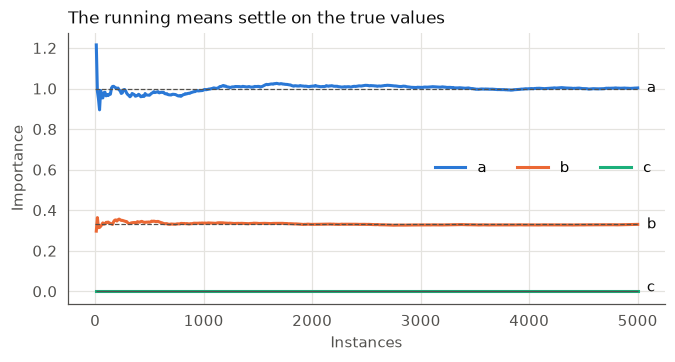

{'a': 1.003, 'b': 0.33, 'c': 0.0}

In [4]:
model = Known()
explainer = lm.importance.PFI(
    model,
    metrics.MAE(),
    imputer=lm.imputer.Marginal(lm.storage.UniformReservoir(seed=1), seed=2),
    tracker=lm.tracker.Mean(),
)
steps, history = track(explainer, model, make_stream(5000), every=10, learn=False)

fig, ax = plt.subplots(figsize=(7, 3.2))
plot_importances(ax, steps, history, "The running means settle on the true values")
ax.hlines([1, 1 / 3], 0, steps[-1], color=MUTED, linewidth=0.8, linestyle="--")
ax.legend(loc="center right", ncols=3)
plt.show()

{feature: round(values[-1], 3) for feature, values in history.items()}

The dashed lines are the true values.

## The values follow the model

So far the model was fixed. A real model learns from the stream, so a feature only matters once the
model has learned to use it. Here, a River model starts from nothing. We set a faster `alpha` than the default, explained below,
to see the start of the stream more clearly.

Call `explainer.learn_one` before `model.learn_one`, so that the instance is new to the model. The
explainer never updates the model: the loop does that.

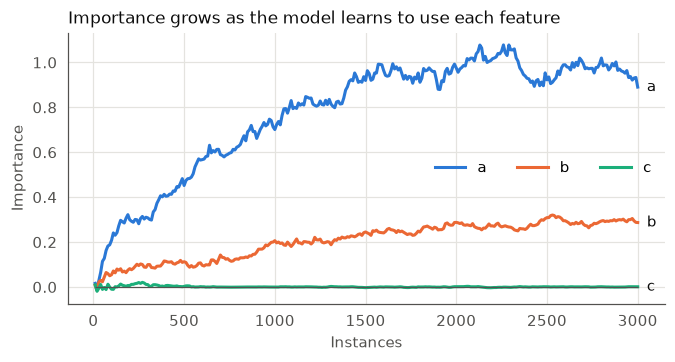

In [5]:
model = linear_model.LinearRegression()
explainer = lm.importance.PFI(model, metrics.MAE(), tracker=lm.tracker.EWMean(alpha=0.01), seed=0)
steps, history = track(explainer, model, make_stream(3000), every=10)

fig, ax = plt.subplots(figsize=(7, 3.2))
plot_importances(ax, steps, history, "Importance grows as the model learns to use each feature")
ax.legend(loc="center right", ncols=3)
plt.show()

## What "recent" means: the storage

Two pieces decide how fast PFI forgets. The first is the storage, which keeps the past instances
that values are taken from. It has a fixed size, so it has to choose what to keep. To see the
difference, we mark where in a stream of 10,000 instances each kept instance comes from.

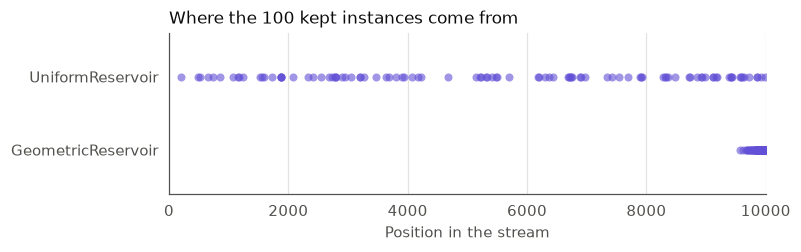

{'GeometricReservoir': 9900, 'UniformReservoir': 5480}

In [6]:
storages = {
    "GeometricReservoir": lm.storage.GeometricReservoir(size=100, seed=0),
    "UniformReservoir": lm.storage.UniformReservoir(size=100, seed=0),
}
for storage in storages.values():
    for i in range(10_000):
        storage.update({"i": i})

fig, ax = plt.subplots(figsize=(7, 1.9))
for row, storage in enumerate(storages.values()):
    kept = [x["i"] for x in storage.instances]
    ax.scatter(kept, [row] * len(kept), s=28, color=OTHERS[0], alpha=0.6, linewidths=0)
ax.set_yticks([0, 1], list(storages))
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(0, 10_000)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Position in the stream")
ax.set_title("Where the 100 kept instances come from")
plt.show()

{name: round(sum(x["i"] for x in s.instances) / len(s)) for name, s in storages.items()}

`UniformReservoir` keeps a fair sample of the whole stream. `GeometricReservoir` lets each new
instance replace a random one, so an instance stays for about `size` steps, and only recent ones are
left. When a stream drifts, values from long ago no longer describe it.

## What "recent" means: the tracker

The second piece is the tracker, which keeps the running mean. `tracker.Mean` weighs all values the
same, and `tracker.EWMean` favours recent ones, with `alpha` setting by how much. It covers about
the last `2 / alpha` values. Here it follows a noisy series that jumps from 0 to 1 halfway:

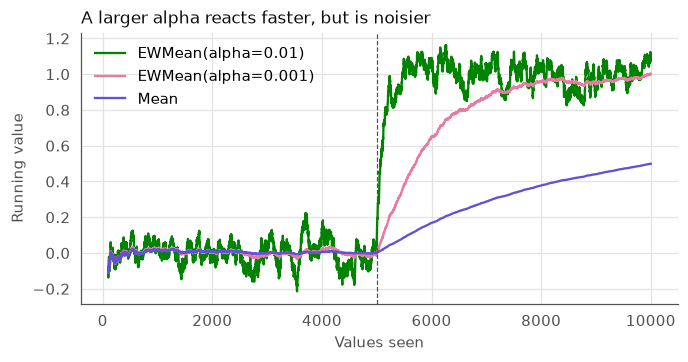

In [7]:
rng = random.Random(0)
series = [(0 if i < 5000 else 1) + rng.gauss(0, 1) for i in range(10_000)]
trackers = {
    "EWMean(alpha=0.01)": (lm.tracker.EWMean(alpha=0.01), OTHERS[2]),
    "EWMean(alpha=0.001)": (lm.tracker.EWMean(alpha=0.001), OTHERS[1]),
    "Mean": (lm.tracker.Mean(), OTHERS[0]),
}

fig, ax = plt.subplots(figsize=(7, 3.2))
for name, (tracker, color) in trackers.items():
    values = []
    for value in series:
        tracker.update(value)
        values.append(tracker.get())
    ax.plot(range(100, len(values)), values[100:], color=color, label=name, linewidth=1.5)
ax.axvline(5000, color=MUTED, linewidth=0.8, linestyle="--")
ax.set_xlabel("Values seen")
ax.set_ylabel("Running value")
ax.set_title("A larger alpha reacts faster, but is noisier")
ax.legend(loc="upper left")
plt.show()

The dashed line marks the jump. The first 100 values are not drawn, as all three lines are very
noisy there. `Mean` never reaches 1, as it still counts the old values. The authors of iPFI found
that an `alpha` between 0.001 and 0.01 works well.

## When the stream drifts

Now the two pieces work together. Halfway through this stream, the target moves from `3a + b` to
`a + 3b`, so `a` and `b` swap roles. The model is the same in both runs and adapts by itself. We only
change how PFI forgets.

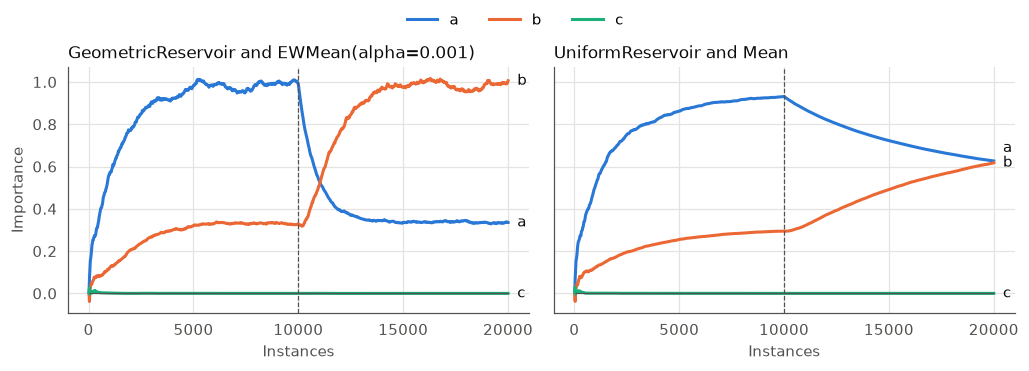

,GeometricReservoir and EWMean(alpha=0.001),UniformReservoir and Mean
a,0.335,0.626
b,1.006,0.618
c,-0.000,0.000


In [8]:
DRIFT = 10_000


def run_drift(imputer, tracker):
    model = linear_model.LinearRegression()
    explainer = lm.importance.PFI(model, metrics.MAE(), imputer=imputer, tracker=tracker)
    return track(explainer, model, make_stream(2 * DRIFT, drift_at=DRIFT), every=20)


runs = {
    "GeometricReservoir and EWMean(alpha=0.001)": run_drift(
        lm.imputer.Marginal(lm.storage.GeometricReservoir(seed=1), seed=2),
        lm.tracker.EWMean(alpha=0.001),
    ),
    "UniformReservoir and Mean": run_drift(
        lm.imputer.Marginal(lm.storage.UniformReservoir(seed=1), seed=2),
        lm.tracker.Mean(),
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, (title, (steps, history)) in zip(axes, runs.items()):
    plot_importances(ax, steps, history, title)
    ax.axvline(DRIFT, color=MUTED, linewidth=0.8, linestyle="--")
    ax.set_xticks(range(0, 2 * DRIFT + 1, 5000))
axes[1].set_ylabel("")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=3)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

pd.DataFrame({name: {f: v[-1] for f, v in run[1].items()} for name, run in runs.items()}).round(3)

The dashed line marks the drift. After it, the true values are 1 for `b` and 1/3 for `a`.

The left panel uses PFI's default pieces. Its lines cross about 1,000 instances after the drift, and
reach the new values after about 4,000. This delay comes from both the model, which has to adapt, and
`alpha`. The right panel averages over the whole stream, so by the end it sees `a` and `b` as about
equal. That is a fair summary of the whole stream, but not of the model at that point.

Use the pieces on the left unless you know that the stream does not change.

## River classifiers and metrics

Everything above works with any River model and metric, without any adapter. The metric decides what
the model is asked for, as in River's own evaluation: `LogLoss` needs probabilities, while `Accuracy`
needs labels.

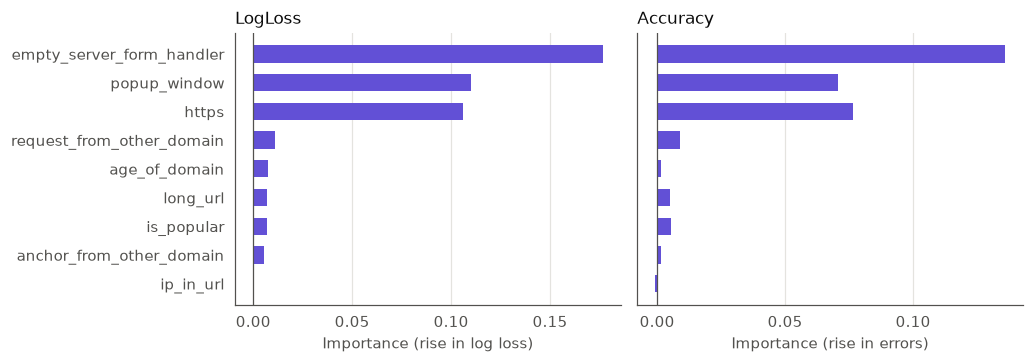

,LogLoss,Accuracy
empty_server_form_handler,0.177,0.136
popup_window,0.110,0.071
https,0.106,0.077
request_from_other_domain,0.011,0.009
age_of_domain,0.007,0.001
long_url,0.007,0.005
is_popular,0.007,0.005
anchor_from_other_domain,0.005,0.002
ip_in_url,-0.000,-0.001


In [9]:
def phishing_importances(metric):
    model = preprocessing.StandardScaler() | linear_model.LogisticRegression()
    explainer = lm.importance.PFI(model, metric, seed=42)
    for x, y in datasets.Phishing():
        explainer.learn_one(x, y)
        model.learn_one(x, y)
    return explainer.importances


frame = pd.DataFrame(
    {
        "LogLoss": phishing_importances(metrics.LogLoss()),
        "Accuracy": phishing_importances(metrics.Accuracy()),
    }
).sort_values("LogLoss")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, name in zip(axes, frame):
    ax.barh(frame.index, frame[name], color=OTHERS[0], height=0.6)
    ax.locator_params(axis="x", nbins=5)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_title(name)
    ax.set_xlabel(f"Importance (rise in {'log loss' if name == 'LogLoss' else 'errors'})")
fig.tight_layout()
plt.show()

frame.sort_values("LogLoss", ascending=False).round(3)

The two metrics are on different scales, so compare the order of the features, not the numbers. Both
agree on which three features matter most. A value just below zero is noise, or a feature that does
not help.

The loss is computed on one instance at a time, so use a metric that makes sense for one instance.
`MAE`, `MSE`, `LogLoss`, `CrossEntropy` and `Accuracy` do. `ROCAUC` and `F1` need many instances, so
they run but do not give useful values.

A metric that does not fit the model gives an error right away:

In [10]:
model = preprocessing.StandardScaler() | linear_model.LinearRegression()
try:
    lm.importance.PFI(model, metrics.LogLoss())
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: LogLoss does not work with Pipeline


## Models with many outputs

A River multi-output model takes and gives a dictionary, with one value per output. `PFI` can explain
it with a metric from `river.metrics.multioutput`, which gives one value per feature.
`lm.multioutput.PerOutput` gives the values of each output instead, with one explainer per output.
Each explainer gets a model with that one output, so its metric is for one output, such as `MAE`.

Here, `y1` is `3a + b` and `y2` is `a + 3b`. We explain the same model both ways.

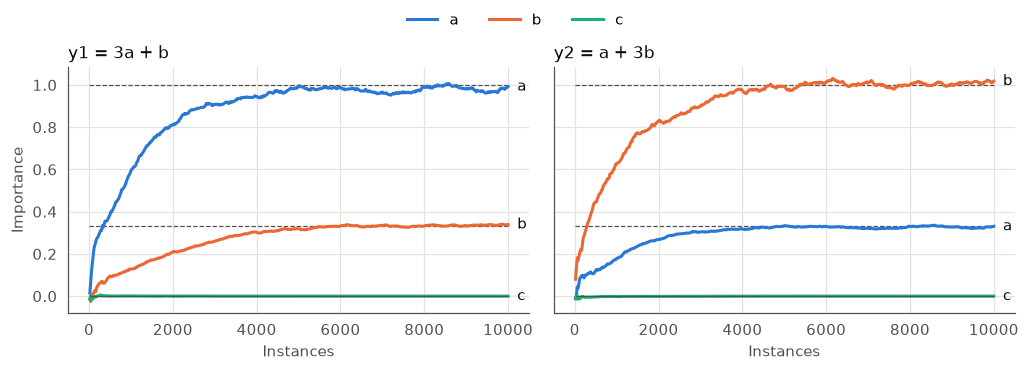

,y1,y2,all outputs
a,0.992,0.331,0.661
b,0.339,1.018,0.679
c,0.000,-0.000,-0.000


In [11]:
def make_two_outputs(n, seed=0):
    """`y1` is `3a + b` and `y2` is `a + 3b`. `c` is never used."""
    for x, y1 in make_stream(n, seed=seed):
        yield x, {"y1": y1, "y2": x["a"] + 3 * x["b"]}


model = multioutput.RegressorChain(linear_model.LinearRegression(), order=["y1", "y2"])
per_output = lm.multioutput.PerOutput(
    model, lambda output: lm.importance.PFI(output, metrics.MAE(), seed=42)
)
all_outputs = lm.importance.PFI(model, metrics.multioutput.MicroAverage(metrics.MAE()), seed=42)

steps, history = [], {"y1": {}, "y2": {}}
for i, (x, y) in enumerate(make_two_outputs(10_000), start=1):
    per_output.learn_one(x, y)
    all_outputs.learn_one(x, y)
    model.learn_one(x, y)
    if i % 20 == 0:
        steps.append(i)
        for output, importances in per_output.importances.items():
            for feature, value in importances.items():
                history[output].setdefault(feature, []).append(value)

titles = {"y1": "y1 = 3a + b", "y2": "y2 = a + 3b"}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, (output, values) in zip(axes, history.items()):
    ax.hlines([1, 1 / 3], 0, steps[-1], color=MUTED, linewidth=0.8, linestyle="--")
    plot_importances(ax, steps, values, titles[output])
axes[1].set_ylabel("")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=3)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

pd.DataFrame({**per_output.importances, "all outputs": all_outputs.importances}).round(3)

The dashed lines are the true values, 1 and 1/3, and each output settles on them. In the table, the
last column gives `a` and `b` about the
same value, 2/3, as it averages over the outputs. So it tells you that the model uses both, but not
that each output relies on a different one.

This model is a chain, so `y2` also takes the prediction of `y1` as a feature. Its own weight on `a` is
only about -0.07, and most of the effect of `a` comes through `y1`. The value above includes that
effect, which is why `a` is still close to 1/3.

Each output has its own explainer, so this takes `n_outputs` times the predictions and state of a model
with one output. Use the last column if that is too slow, or if you only need one value per feature.

## What it costs

Each instance takes one prediction as it is, and then `n_samples` predictions per feature.

In [12]:
class Counting(Known):
    calls = 0

    def predict_one(self, x):
        self.calls += 1
        return super().predict_one(x)


rows = []
for n_samples in (1, 5, 20):
    estimates = []
    for seed in range(20):
        model = Counting()
        explainer = lm.importance.PFI(
            model, metrics.MAE(), tracker=lm.tracker.Mean(), n_samples=n_samples, seed=seed
        )
        for x, y in make_stream(500, seed=seed):
            explainer.learn_one(x, y)
        estimates.append(explainer.importances["a"])
    rows.append(
        {
            "n_samples": n_samples,
            "predictions per instance": model.calls / 499,
            "mean of a": sum(estimates) / len(estimates),
            "spread of a (std)": pd.Series(estimates).std(),
        }
    )
pd.DataFrame(rows).set_index("n_samples").round(3)

,predictions per instance,mean of a,spread of a (std)
n_samples,,,
1,4.0,1.012,0.034
5,16.0,0.996,0.025
20,61.0,1.002,0.024


This is 3 features over 500 instances and 20 seeds, where the true value of `a` is 1. More samples
give less noise, but soon stop helping: going from 5 to 20 takes almost 4 times the predictions for
about the same spread, since part of it comes from the stream itself. With a slow model or many
features, keep `n_samples=1`, as the running mean already averages over the stream.

## Does it match batch PFI?

As a last check, we freeze a trained model and compare with the usual batch PFI, which shuffles each
column of a fixed dataset. If nothing changes, the two should agree.

In [13]:
stream = list(datasets.synth.Friedman(seed=7).take(12_000))
model = preprocessing.StandardScaler() | linear_model.LinearRegression()
for x, y in stream[:8000]:
    model.learn_one(x, y)
test = stream[8000:]


def mae(rows):
    return sum(abs(y - model.predict_one(x)) for x, y in rows) / len(rows)


rng = random.Random(0)
batch = {}
for feature in test[0][0]:
    total = 0.0
    for _ in range(10):
        values = [x[feature] for x, _ in test]
        rng.shuffle(values)
        total += mae([({**x, feature: v}, y) for (x, y), v in zip(test, values)])
    batch[feature] = total / 10 - mae(test)

explainer = lm.importance.PFI(
    model,
    metrics.MAE(),
    imputer=lm.imputer.Marginal(lm.storage.UniformReservoir(size=500, seed=1), seed=2),
    tracker=lm.tracker.Mean(),
    n_samples=5,
)
for x, y in test:
    explainer.learn_one(x, y)

pd.DataFrame({"batch": batch, "incremental": explainer.importances}).round(3)

,batch,incremental
0,0.826,0.794
1,0.690,0.689
2,0.001,0.001
3,1.614,1.620
4,0.545,0.524
5,0.003,0.002
6,-0.000,-0.004
7,-0.010,-0.008
8,0.000,0.001
9,0.000,0.004


The two agree closely, with a largest difference of about 0.03. Unlike batch PFI, the incremental
version needs no second pass over the data, and gives values while the stream is running.

## Summary

| Question | Answer |
|---|---|
| What does a value mean? | How much the loss rises when the feature's value is swapped. Near zero means the model does not rely on it. |
| When do I call it? | `explainer.learn_one(x, y)` before `model.learn_one(x, y)`. |
| Where do I read it? | `explainer.importances`, at any time. |
| What does it cost? | `1 + n_features * n_samples` predictions per instance. |
| Model with many outputs | `lm.multioutput.PerOutput` for the values of each output, at `n_outputs` times the cost. |
| Stream that changes | The default pieces: `GeometricReservoir` and `EWMean`. |
| Stream that does not change | `UniformReservoir` and `Mean`. |

The [API reference](../docs/api/index.md) has the details.